# Lab 14 — Vector Databases with Image & Text Embeddings
**Spring 2026 | Database Lab**

This notebook covers all three tasks:
- **Task 1:** Image Similarity Search
- **Task 2:** Classification via KNN (no model training)
- **Task 3:** Cross-Modal Search (Text → Image)

Both **Pinecone** and **MongoDB Atlas** are used as vector databases.

> Set PINECONE_API_KEY and MONGO_URI as environment variables before running (see .env.example).

## 0. Install Dependencies

In [8]:
!pip install pinecone pymongo transformers torch Pillow requests tqdm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 742.8/742.8 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 280.7/280.7 kB 21.6 MB/s eta 0:00:00


## 0.5. Extract Dataset

In [ ]:
import zipfile, os

ZIP_PATH    = "animal_dataset.zip"
EXTRACT_DIR = "."

# ── Google Colab: upload the zip first ──────────────────────────────
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import files
    print("Running in Colab — please upload animal_dataset.zip when prompted.")
    uploaded = files.upload()   # triggers file picker
    ZIP_PATH = list(uploaded.keys())[0]
else:
    # ── Local Jupyter: zip must already be in the same folder as this notebook
    if not os.path.exists(ZIP_PATH):
        raise FileNotFoundError(
            f"'{ZIP_PATH}' not found. Place animal_dataset.zip in the same "
            "folder as this notebook and re-run."
        )

# ── Extract ─────────────────────────────────────────────────────────
if not os.path.isdir("animal_dataset"):
    print(f"Extracting {ZIP_PATH} ...")
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(EXTRACT_DIR)
    print("Extraction complete.")
else:
    print("animal_dataset/ already exists, skipping extraction.")

# ── Verify ──────────────────────────────────────────────────────────
expected_classes = [
    "Butterfly", "Cat", "Chicken", "Cow", "Dog",
    "Elephant", "Horse", "Sheep", "Spider", "Squirrel"
]
print()
total = 0
for cls in expected_classes:
    cls_path = os.path.join("animal_dataset", cls)
    count    = len([f for f in os.listdir(cls_path) if f.endswith(".jpg")]) if os.path.isdir(cls_path) else 0
    total   += count
    status   = "✓" if count == 50 else f"⚠ expected 50"
    print(f"  {cls:<12} {count} images  {status}")
print(f"\nTotal: {total} images across {len(expected_classes)} classes.")

Running in Colab — please upload animal_dataset.zip when prompted.


Saving animal_dataset.zip to animal_dataset.zip
Extracting animal_dataset.zip ...
Extraction complete.

  Butterfly    50 images  ✓
  Cat          50 images  ✓
  Chicken      50 images  ✓
  Cow          50 images  ✓
  Dog          50 images  ✓
  Elephant     50 images  ✓
  Horse        50 images  ✓
  Sheep        50 images  ✓
  Spider       50 images  ✓
  Squirrel     50 images  ✓

Total: 500 images across 10 classes.


## 1. Configuration — Fill Your API Keys Here

In [15]:
import os
# =============================================
#  Credentials come from environment variables (see .env.example)
# =============================================

PINECONE_API_KEY    = os.environ["PINECONE_API_KEY"]
PINECONE_ENV        = "us-east-1"   # e.g. us-east-1, gcp-starter
PINECONE_INDEX_NAME = "openlab"

MONGO_URI           = os.environ["MONGO_URI"]
MONGO_DB_NAME       = "lab14"
MONGO_COLLECTION    = "animal_embeddings"

# Path to your animal images folder
# Expected structure: animal_dataset/Cat/0050.jpg, animal_dataset/Dog/0100.jpg ...
IMAGES_DIR          = "./animal_dataset"

EMBEDDING_DIM       = 512   # CLIP ViT-B/32 output dimension
TOP_K               = 5     # Number of results to retrieve

## 2. Imports & CLIP Model Setup

In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image
from collections import Counter
from tqdm import tqdm

import torch
from transformers import CLIPProcessor, CLIPModel

# Load CLIP model (ViT-B/32)
print("Loading CLIP model...")
clip_model     = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
clip_model.eval()
print("CLIP model loaded successfully.")

Loading CLIP model...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

... (5 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP model loaded successfully.


## 3. Embedding Helper Functions

In [ ]:
def get_image_embedding(image_path: str) -> list:
    """Generate a CLIP embedding for a single image."""
    image = Image.open(image_path).convert("RGB")
    inputs = clip_processor(images=image, return_tensors="pt")
    with torch.no_grad():
        outputs = clip_model.vision_model(**inputs)
        features = outputs.pooler_output  # extract raw tensor
        features = clip_model.visual_projection(features)
    # L2-normalize so cosine similarity == dot product
    features = features / features.norm(dim=-1, keepdim=True)
    return features[0].tolist()


def get_text_embedding(text: str) -> list:
    """Generate a CLIP embedding for a text string."""
    inputs = clip_processor(text=[text], return_tensors="pt", padding=True)
    with torch.no_grad():
        outputs = clip_model.text_model(**inputs)
        features = outputs.pooler_output  # extract raw tensor
        features = clip_model.text_projection(features)
    features = features / features.norm(dim=-1, keepdim=True)
    return features[0].tolist()


def load_dataset(images_dir: str) -> list:
    """
    Loads images from the animal_dataset folder structure:
        animal_dataset/
            Cat/0050.jpg ... 0099.jpg
            Dog/0100.jpg ... 0149.jpg
            Horse/0300.jpg ... 0349.jpg
            ...

    Each image gets a unique ID of the form 'Cat_0050' to avoid
    collisions — multiple classes share the same numeric filenames.
    Returns a list of dicts: {id, path, label, filename}
    """
    records = []
    supported = ("*.jpg", "*.jpeg", "*.png", "*.webp")
    for label_dir in sorted(os.listdir(images_dir)):
        full_label_dir = os.path.join(images_dir, label_dir)
        if not os.path.isdir(full_label_dir):
            continue
        label = label_dir   # preserve original casing e.g. 'Cat', 'Horse'
        for ext in supported:
            for img_path in sorted(glob.glob(os.path.join(full_label_dir, ext))):
                filename = os.path.splitext(os.path.basename(img_path))[0]  # e.g. '0050'
                records.append({
                    "id":       f"{label}_{filename}",   # e.g. 'Cat_0050'
                    "path":     img_path,
                    "label":    label,
                    "filename": filename
                })
    labels_found = sorted(set(r['label'] for r in records))
    print(f"Found {len(records)} images across {len(labels_found)} classes: {labels_found}")
    return records


def display_images(image_paths: list, titles: list = None, cols: int = 5):
    """Utility to display a list of images in a grid."""
    n = len(image_paths)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
    axes = np.array(axes).flatten()
    for i, ax in enumerate(axes):
        if i < n:
            img = mpimg.imread(image_paths[i])
            ax.imshow(img)
            ax.axis("off")
            if titles:
                ax.set_title(titles[i], fontsize=9)
        else:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

## 4. Load Dataset & Generate All Embeddings

In [ ]:
records = load_dataset(IMAGES_DIR)

print("Generating embeddings for all images...")
for rec in tqdm(records):
    rec["embedding"] = get_image_embedding(rec["path"])

print(f"Done. Each embedding has {len(records[0]['embedding'])} dimensions.")

Found 500 images across 10 classes: ['Butterfly', 'Cat', 'Chicken', 'Cow', 'Dog', 'Elephant', 'Horse', 'Sheep', 'Spider', 'Squirrel']
Generating embeddings for all images...



100%|██████████| 500/500 [01:55<00:00,  4.31it/s]

Done. Each embedding has 512 dimensions.


---
# PART A — Pinecone Vector Database
---

## A1. Connect to Pinecone & Create Index

In [9]:
from pinecone import Pinecone, ServerlessSpec

pc = Pinecone(api_key=PINECONE_API_KEY)

# Create index if it doesn't exist
existing_indexes = [idx.name for idx in pc.list_indexes()]
if PINECONE_INDEX_NAME not in existing_indexes:
    print(f"Creating Pinecone index '{PINECONE_INDEX_NAME}'...")
    pc.create_index(
        name=PINECONE_INDEX_NAME,
        dimension=EMBEDDING_DIM,
        metric="cosine",
        spec=ServerlessSpec(cloud="aws", region=PINECONE_ENV)
    )
else:
    print(f"Index '{PINECONE_INDEX_NAME}' already exists.")

pine_index = pc.Index(PINECONE_INDEX_NAME)
print("Connected to Pinecone index.")
print(pine_index.describe_index_stats())

## A2. Upsert All Embeddings into Pinecone

In [10]:
# Upsert in batches of 100
BATCH_SIZE = 100
vectors = [
    {
        "id":       rec["id"],
        "values":   rec["embedding"],
        "metadata": {"label": rec["label"], "path": rec["path"]}
    }
    for rec in records
]

for i in tqdm(range(0, len(vectors), BATCH_SIZE), desc="Upserting to Pinecone"):
    pine_index.upsert(vectors=vectors[i:i+BATCH_SIZE])

print("All embeddings upserted to Pinecone.")
print(pine_index.describe_index_stats())

Upserting to Pinecone: 100%|██████████| 5/5 [00:02<00:00,  2.11it/s]

## A3. Task 1 (Pinecone) — Image Similarity Search

Query image: ./animal_dataset/Butterfly/0000.jpg  |  Label: Butterfly

Top 5 similar images:
  ID: Butterfly_0031  |  Label: Butterfly  |  Score: 0.9215
  ID: Butterfly_0012  |  Label: Butterfly  |  Score: 0.9175
  ID: Butterfly_0027  |  Label: Butterfly  |  Score: 0.9124
  ID: Butterfly_0007  |  Label: Butterfly  |  Score: 0.9019
  ID: Butterfly_0041  |  Label: Butterfly  |  Score: 0.8799

--- Query Image ---


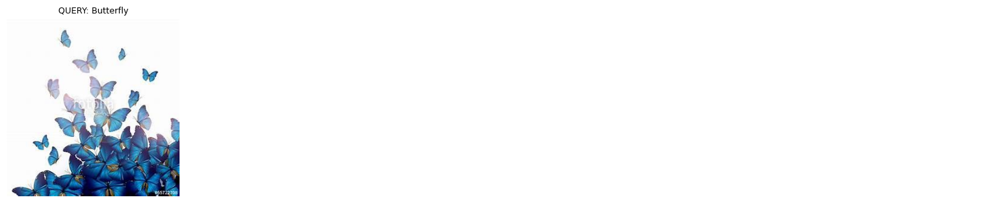

--- Top Similar Images (Pinecone) ---


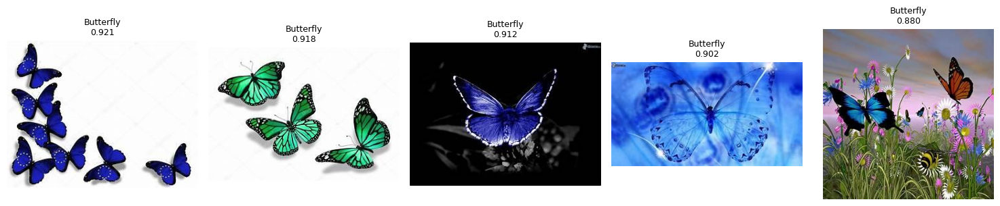

In [11]:
# Pick a query image — change this path to any image in your dataset
query_record = records[0]   # <-- change index to pick a different query image
query_path   = query_record["path"]
query_label  = query_record["label"]
query_id     = query_record["id"]

print(f"Query image: {query_path}  |  Label: {query_label}")

query_embedding = get_image_embedding(query_path)

results = pine_index.query(
    vector=query_embedding,
    top_k=TOP_K + 1,   # +1 because the query itself may be returned
    include_metadata=True
)

# Filter out the query image itself
matches = [m for m in results["matches"] if m["id"] != query_id][:TOP_K]

print(f"\nTop {TOP_K} similar images:")
for m in matches:
    print(f"  ID: {m['id']}  |  Label: {m['metadata']['label']}  |  Score: {m['score']:.4f}")

# Visualize
result_paths  = [m["metadata"]["path"]  for m in matches]
result_titles = [f"{m['metadata']['label']}\n{m['score']:.3f}" for m in matches]

print("\n--- Query Image ---")
display_images([query_path], titles=[f"QUERY: {query_label}"])

print("--- Top Similar Images (Pinecone) ---")
display_images(result_paths, titles=result_titles)

## A4. Task 2 (Pinecone) — Classification via KNN

True label:      Butterfly
Predicted label: Butterfly

Neighbors used for voting:
  Label: Butterfly  |  Score: 0.9207
  Label: Butterfly  |  Score: 0.9091
  Label: Butterfly  |  Score: 0.9055
  Label: Butterfly  |  Score: 0.8940
  Label: Butterfly  |  Score: 0.8935

--- Test Image ---


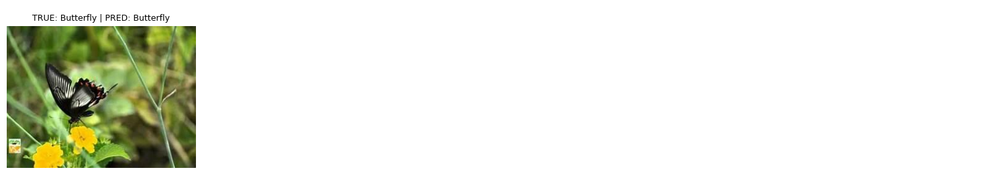

--- KNN Neighbors (Pinecone) ---


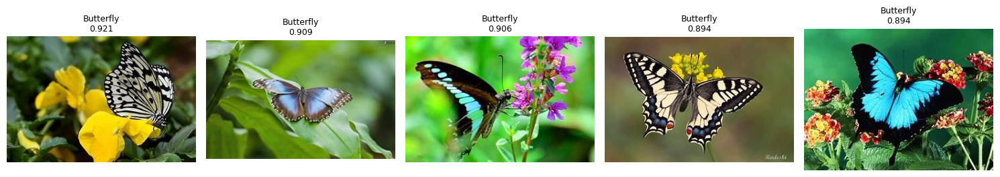

In [12]:
def classify_image_pinecone(image_path: str, k: int = 5) -> str:
    """Classify an image using KNN voting via Pinecone."""
    embedding = get_image_embedding(image_path)
    results = pine_index.query(
        vector=embedding,
        top_k=k + 1,
        include_metadata=True
    )
    neighbors = results["matches"][1:k+1]  # skip self if present
    labels = [n["metadata"]["label"] for n in neighbors]
    predicted = Counter(labels).most_common(1)[0][0]
    return predicted, neighbors


# Test on a sample image (use one NOT in the index for a real test,
# or just use any record to verify the logic)
test_record = records[10]   # <-- change this
test_path   = test_record["path"]
true_label  = test_record["label"]

predicted_label, neighbors = classify_image_pinecone(test_path, k=TOP_K)

print(f"True label:      {true_label}")
print(f"Predicted label: {predicted_label}")
print(f"\nNeighbors used for voting:")
for n in neighbors:
    print(f"  Label: {n['metadata']['label']}  |  Score: {n['score']:.4f}")

# Visualize the test image and its neighbors
neighbor_paths  = [n["metadata"]["path"]  for n in neighbors]
neighbor_titles = [f"{n['metadata']['label']}\n{n['score']:.3f}" for n in neighbors]

print("\n--- Test Image ---")
display_images([test_path], titles=[f"TRUE: {true_label} | PRED: {predicted_label}"])

print("--- KNN Neighbors (Pinecone) ---")
display_images(neighbor_paths, titles=neighbor_titles)

## A5. Task 3 (Pinecone) — Cross-Modal Search (Text → Image)


Text Query: 'a horse running in a field'
  Label: Horse  |  Score: 0.3000
  Label: Horse  |  Score: 0.2967
  Label: Horse  |  Score: 0.2958
  Label: Horse  |  Score: 0.2869
  Label: Horse  |  Score: 0.2830


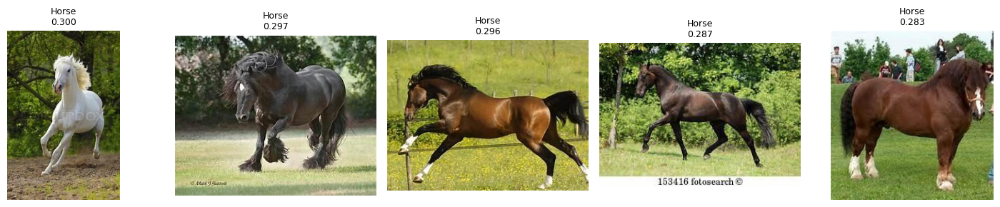


Text Query: 'a cat sitting'
  Label: Cat  |  Score: 0.2716
  Label: Cat  |  Score: 0.2648
  Label: Cat  |  Score: 0.2645
  Label: Cat  |  Score: 0.2640
  Label: Cat  |  Score: 0.2637


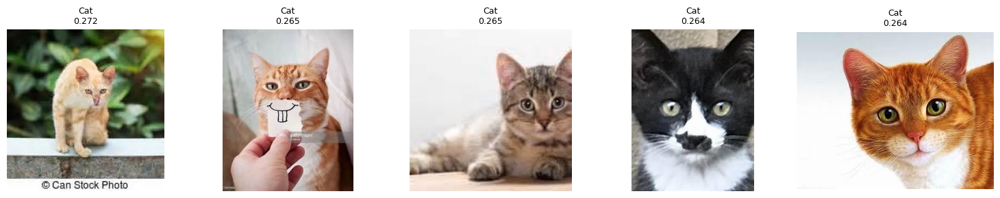


Text Query: 'a large elephant'
  Label: Elephant  |  Score: 0.3280
  Label: Elephant  |  Score: 0.3185
  Label: Elephant  |  Score: 0.3182
  Label: Elephant  |  Score: 0.3150
  Label: Elephant  |  Score: 0.3101


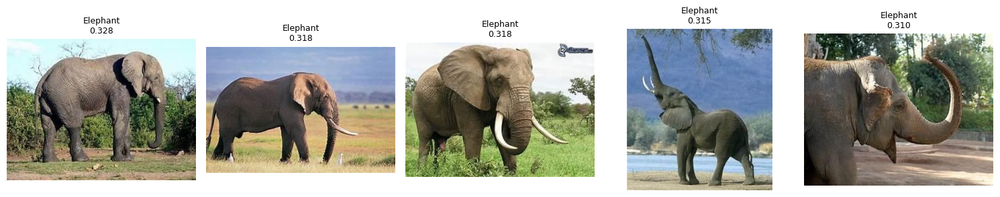


Text Query: 'a colorful butterfly on a flower'
  Label: Butterfly  |  Score: 0.3138
  Label: Butterfly  |  Score: 0.3048
  Label: Butterfly  |  Score: 0.3044
  Label: Butterfly  |  Score: 0.3029
  Label: Butterfly  |  Score: 0.3027


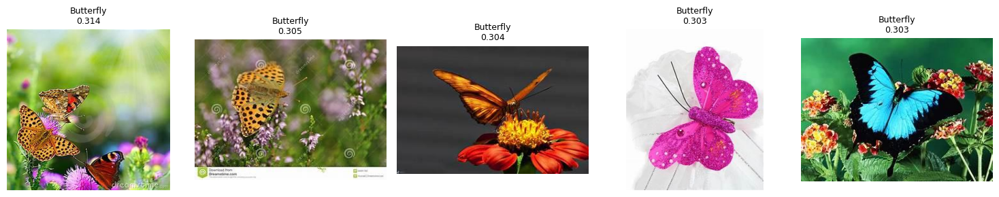


Text Query: 'a fluffy dog'
  Label: Dog  |  Score: 0.3084
  Label: Dog  |  Score: 0.2950
  Label: Dog  |  Score: 0.2868
  Label: Dog  |  Score: 0.2717
  Label: Dog  |  Score: 0.2699


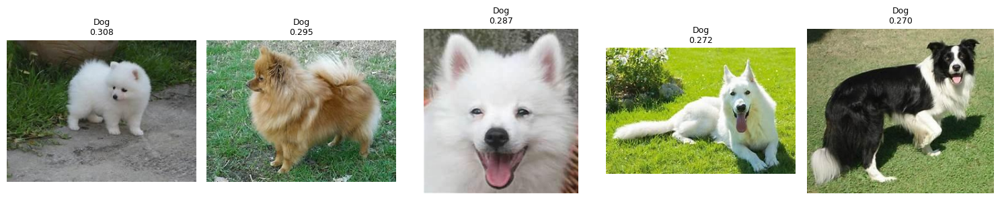

In [13]:
def text_to_image_pinecone(text_query: str, k: int = 5):
    """Search images using a natural language text query via Pinecone."""
    text_emb = get_text_embedding(text_query)
    results  = pine_index.query(
        vector=text_emb,
        top_k=k,
        include_metadata=True
    )
    return results["matches"]


# Text queries matching actual dataset classes
text_queries = [
    "a horse running in a field",
    "a cat sitting",
    "a large elephant",
    "a colorful butterfly on a flower",
    "a fluffy dog"
]

for query_text in text_queries:
    print(f"\n{'='*50}")
    print(f"Text Query: '{query_text}'")
    print(f"{'='*50}")

    matches = text_to_image_pinecone(query_text, k=TOP_K)

    for m in matches:
        print(f"  Label: {m['metadata']['label']}  |  Score: {m['score']:.4f}")

    paths  = [m["metadata"]["path"]  for m in matches]
    titles = [f"{m['metadata']['label']}\n{m['score']:.3f}" for m in matches]
    display_images(paths, titles=titles)

---
# PART B — MongoDB Atlas Vector Search
---

## B1. Connect to MongoDB Atlas & Store Embeddings

> Before running, create a **Vector Search Index** in MongoDB Atlas:
> 1. Go to your cluster → **Search** tab → **Create Search Index**
> 2. Choose **Vector Search**
> 3. Use this JSON definition:
> ```json
> {
>   "fields": [{
>     "type": "vector",
>     "path": "embedding",
>     "numDimensions": 512,
>     "similarity": "cosine"
>   }]
> }
> ```
> 4. Name the index: `vector_index`

## B2. Task 1 (MongoDB) — Image Similarity Search

In [23]:
from pymongo import MongoClient

mongo_client = MongoClient(MONGO_URI)
mongo_db     = mongo_client[MONGO_DB_NAME]
mongo_col    = mongo_db[MONGO_COLLECTION]

# Insert all embeddings (drop existing to avoid duplicates)
mongo_col.drop()

docs = [
    {
        "_id":       rec["id"],
        "path":      rec["path"],
        "label":     rec["label"],
        "embedding": rec["embedding"]
    }
    for rec in records
]

mongo_col.insert_many(docs)
print(f"Inserted {mongo_col.count_documents({})} documents into MongoDB Atlas.")

Inserted 500 documents into MongoDB Atlas.


Query: ./animal_dataset/Butterfly/0000.jpg  |  Label: Butterfly

Top 5 similar images (MongoDB):
  ID: Butterfly_0031  |  Label: Butterfly  |  Score: 0.9606
  ID: Butterfly_0012  |  Label: Butterfly  |  Score: 0.9582
  ID: Butterfly_0027  |  Label: Butterfly  |  Score: 0.9561
  ID: Butterfly_0007  |  Label: Butterfly  |  Score: 0.9510
  ID: Butterfly_0041  |  Label: Butterfly  |  Score: 0.9398


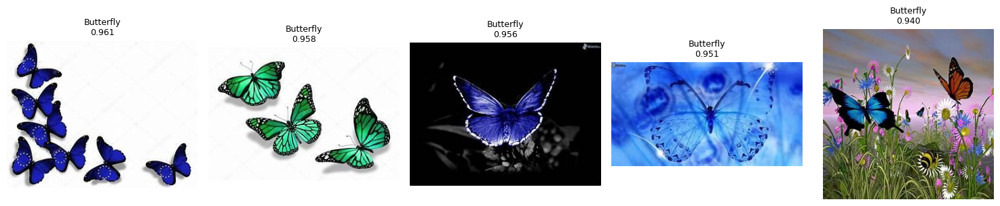

In [26]:
query_embedding_m = get_image_embedding(query_path)
mongo_matches = mongo_vector_search(query_embedding_m, k=TOP_K, exclude_id=query_id)

print(f"Query: {query_path}  |  Label: {query_label}")
print(f"\nTop {TOP_K} similar images (MongoDB):")

if not mongo_matches:
    print("No results returned — vector index may still be syncing. Wait 1-2 mins and re-run.")
else:
    for r in mongo_matches:
        print(f"  ID: {r['_id']}  |  Label: {r['label']}  |  Score: {r['score']:.4f}")
    m_paths  = [r["path"]  for r in mongo_matches]
    m_titles = [f"{r['label']}\n{r['score']:.3f}" for r in mongo_matches]
    display_images(m_paths, titles=m_titles)

## B3. Task 2 (MongoDB) — Classification via KNN

True label:      Butterfly
Predicted label: Butterfly

Neighbors:
  Label: Butterfly  |  Score: 1.0000
  Label: Butterfly  |  Score: 0.9607
  Label: Butterfly  |  Score: 0.9546
  Label: Butterfly  |  Score: 0.9533
  Label: Butterfly  |  Score: 0.9471


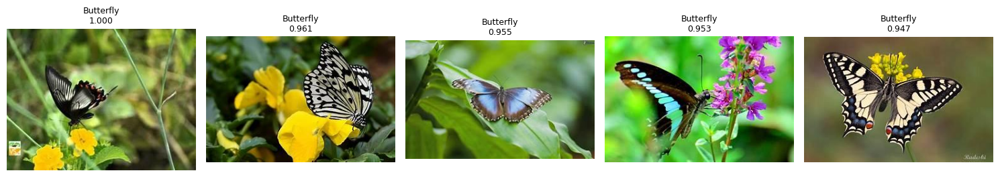

In [27]:
def classify_image_mongo(image_path: str, k: int = 5):
    """Classify an image using KNN voting via MongoDB Atlas."""
    embedding = get_image_embedding(image_path)
    neighbors = mongo_vector_search(embedding, k=k)
    labels    = [n["label"] for n in neighbors]
    predicted = Counter(labels).most_common(1)[0][0]
    return predicted, neighbors


predicted_label_m, neighbors_m = classify_image_mongo(test_path, k=TOP_K)

print(f"True label:      {true_label}")
print(f"Predicted label: {predicted_label_m}")
print(f"\nNeighbors:")
for n in neighbors_m:
    print(f"  Label: {n['label']}  |  Score: {n['score']:.4f}")

n_paths  = [n["path"]  for n in neighbors_m]
n_titles = [f"{n['label']}\n{n['score']:.3f}" for n in neighbors_m]
display_images(n_paths, titles=n_titles)

## B4. Task 3 (MongoDB) — Cross-Modal Search (Text → Image)


Text Query: 'a horse running in a field'
  Label: Horse  |  Score: 0.6488
  Label: Horse  |  Score: 0.6479
  Label: Horse  |  Score: 0.6476
  Label: Horse  |  Score: 0.6431
  Label: Horse  |  Score: 0.6417


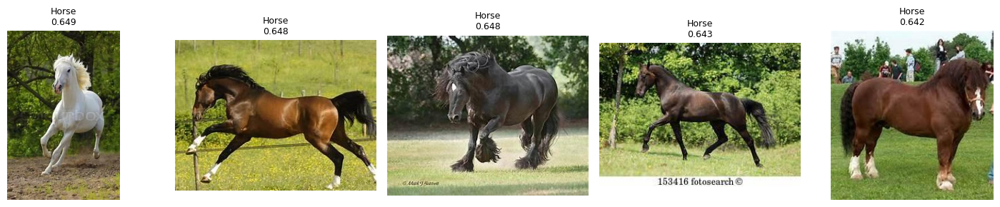


Text Query: 'a cat sitting'
  Label: Cat  |  Score: 0.6352
  Label: Cat  |  Score: 0.6320
  Label: Cat  |  Score: 0.6320
  Label: Cat  |  Score: 0.6319
  Label: Cat  |  Score: 0.6313


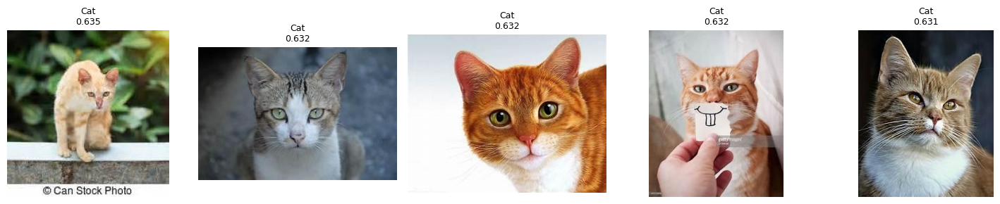


Text Query: 'a large elephant'
  Label: Elephant  |  Score: 0.6643
  Label: Elephant  |  Score: 0.6593
  Label: Elephant  |  Score: 0.6591
  Label: Elephant  |  Score: 0.6579
  Label: Elephant  |  Score: 0.6553


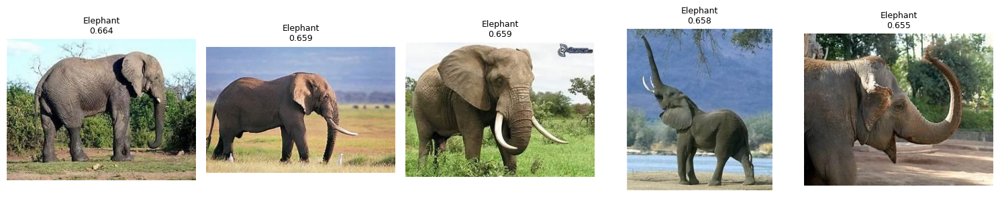


Text Query: 'a colorful butterfly on a flower'
  Label: Butterfly  |  Score: 0.6573
  Label: Butterfly  |  Score: 0.6534
  Label: Butterfly  |  Score: 0.6522
  Label: Butterfly  |  Score: 0.6519
  Label: Butterfly  |  Score: 0.6515


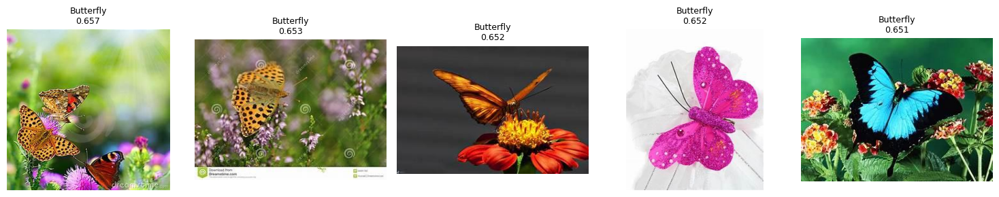


Text Query: 'a fluffy dog'
  Label: Dog  |  Score: 0.6544
  Label: Dog  |  Score: 0.6483
  Label: Dog  |  Score: 0.6431
  Label: Dog  |  Score: 0.6351
  Label: Dog  |  Score: 0.6348


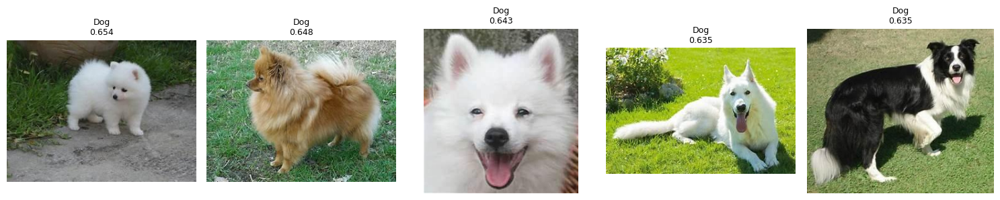

In [28]:
for query_text in text_queries:
    print(f"\n{'='*50}")
    print(f"Text Query: '{query_text}'")
    print(f"{'='*50}")

    text_emb_m     = get_text_embedding(query_text)
    mongo_results  = mongo_vector_search(text_emb_m, k=TOP_K)

    for r in mongo_results:
        print(f"  Label: {r['label']}  |  Score: {r['score']:.4f}")

    t_paths  = [r["path"]  for r in mongo_results]
    t_titles = [f"{r['label']}\n{r['score']:.3f}" for r in mongo_results]
    display_images(t_paths, titles=t_titles)

---
# Comparison: Pinecone vs MongoDB Atlas
---

In [29]:
import time

sample_embedding = records[0]["embedding"]

# Time Pinecone
start = time.time()
for _ in range(5):
    pine_index.query(vector=sample_embedding, top_k=TOP_K, include_metadata=True)
pine_avg_ms = (time.time() - start) / 5 * 1000

# Time MongoDB
start = time.time()
for _ in range(5):
    mongo_vector_search(sample_embedding, k=TOP_K)
mongo_avg_ms = (time.time() - start) / 5 * 1000

print("====== Performance Comparison ======")
print(f"Pinecone  avg query time: {pine_avg_ms:.1f} ms")
print(f"MongoDB   avg query time: {mongo_avg_ms:.1f} ms")
print()
print("====== Feature Comparison ======")
print(f"{'Feature':<30} {'Pinecone':<20} {'MongoDB Atlas':<20}")
print("-" * 70)
rows = [
    ("Purpose",            "Vector-native DB",    "General + Vector Search"),
    ("Setup complexity",   "Low",                 "Medium (index config)"),
    ("Metadata storage",   "Limited",             "Full document storage"),
    ("Query syntax",       "Simple SDK",          "MongoDB aggregation"),
    ("Free tier",          "Yes (Serverless)",    "Yes (M0 cluster)"),
    ("Best for",           "Pure vector search",  "Hybrid data + vectors"),
]
for feat, pine, mongo in rows:
    print(f"{feat:<30} {pine:<20} {mongo:<20}")

====== Performance Comparison ======
Pinecone  avg query time: 259.8 ms
MongoDB   avg query time: 236.9 ms

====== Feature Comparison ======
Feature                        Pinecone             MongoDB Atlas       
----------------------------------------------------------------------
Purpose                        Vector-native DB     General + Vector Search
Setup complexity               Low                  Medium (index config)
Metadata storage               Limited              Full document storage
Query syntax                   Simple SDK           MongoDB aggregation 
Free tier                      Yes (Serverless)     Yes (M0 cluster)    
Best for                       Pure vector search   Hybrid data + vectors


## Cleanup (Optional)

In [ ]:
# Uncomment to delete resources after submission

# pc.delete_index(PINECONE_INDEX_NAME)
# print("Pinecone index deleted.")

# mongo_col.drop()
# mongo_client.close()
# print("MongoDB collection dropped.")

In [24]:
mongo_col.drop()
docs = [
    {
        "_id":       rec["id"],
        "path":      rec["path"],
        "label":     rec["label"],
        "embedding": rec["embedding"]
    }
    for rec in records
]
mongo_col.insert_many(docs)
print(f"Inserted: {mongo_col.count_documents({})} documents")

Inserted: 500 documents


In [25]:
print(mongo_col.count_documents({}))  # must print 500


500
